# Bond Analytics — Spread & Rating Analysis
Connects to Silver and Gold layers in Postgres to analyze HY spreads and bond ratings.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sqlalchemy import create_engine

DB_USER = os.environ.get('POSTGRES_USER', 'admin')
DB_PASS = os.environ.get('POSTGRES_PASSWORD', 'admin')
DB_NAME = os.environ.get('BONDS_DB', 'bonds_db')
DB_HOST = 'localhost'
DB_PORT = '5432'

engine = create_engine(f'postgresql://{DB_USER}:{DB_PASS}@{DB_HOST}:{DB_PORT}/{DB_NAME}')
print('Connected to', DB_NAME)

Connected to bonds_db


## 1. HY Spread — Monthly Trend (Gold layer)

In [2]:
df_monthly = pd.read_sql("""
    SELECT month, avg_spread, min_spread, max_spread, observation_count
    FROM gold.fact_spread_monthly
    WHERE series_id = 'BAMLH0A0HYM2'
    ORDER BY month
""", engine)

df_monthly['month'] = pd.to_datetime(df_monthly['month'])
df_monthly.tail()

,month,avg_spread,min_spread,max_spread,observation_count
32,2026-02-01,2.92,2.81,3.12,21
33,2026-03-01,3.19,2.97,3.46,22
34,2026-04-01,2.93,2.82,3.17,22
35,2026-05-01,2.77,2.71,2.86,22
36,2026-06-01,2.75,2.71,2.80,9


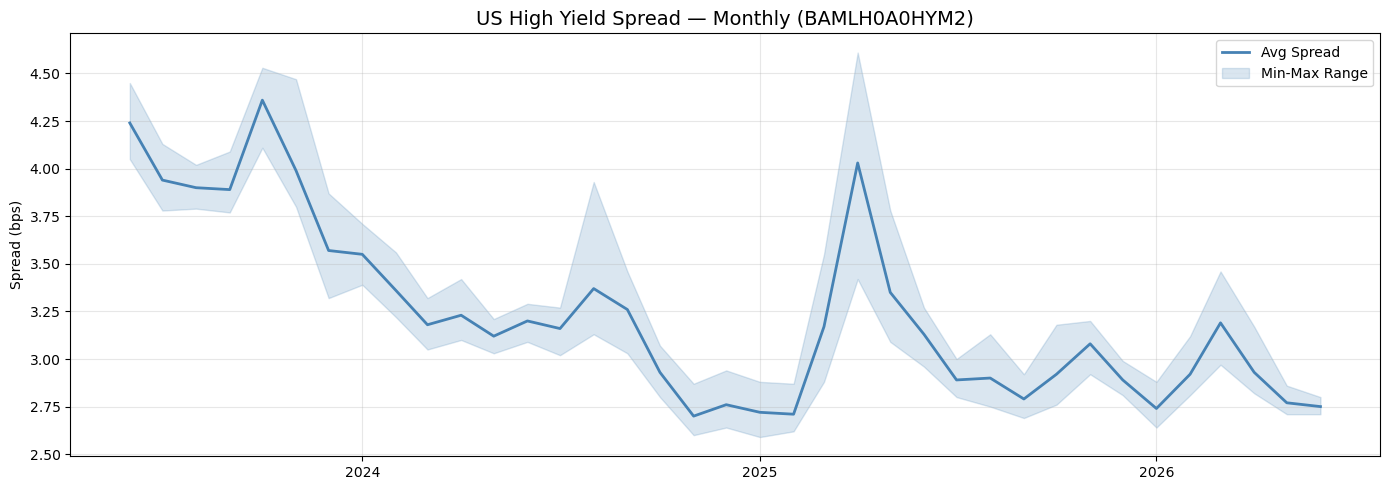

In [3]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(df_monthly['month'], df_monthly['avg_spread'], label='Avg Spread', color='steelblue', linewidth=2)
ax.fill_between(df_monthly['month'], df_monthly['min_spread'], df_monthly['max_spread'],
                alpha=0.2, color='steelblue', label='Min-Max Range')

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.set_title('US High Yield Spread — Monthly (BAMLH0A0HYM2)', fontsize=14)
ax.set_ylabel('Spread (bps)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 2. Spread Volatility — Which years were most volatile?

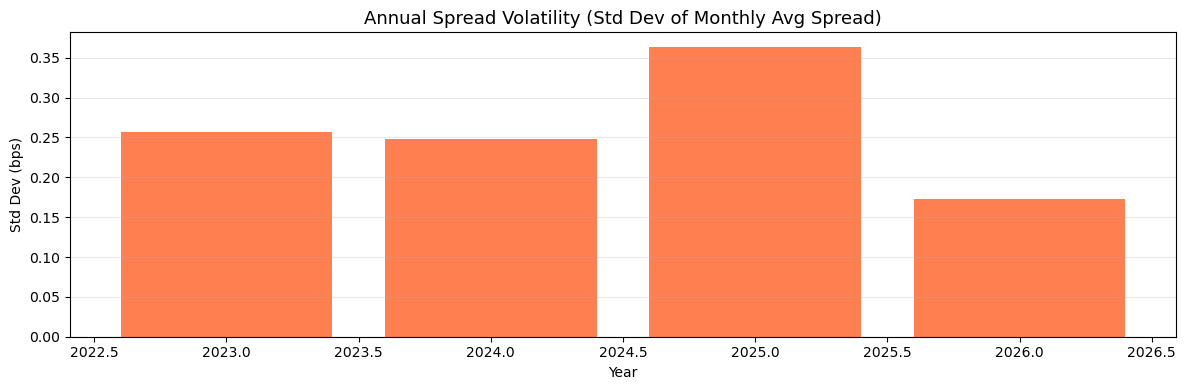

In [4]:
df_monthly['year'] = df_monthly['month'].dt.year
df_vol = df_monthly.groupby('year')['avg_spread'].std().reset_index()
df_vol.columns = ['year', 'spread_std']

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(df_vol['year'], df_vol['spread_std'], color='coral')
ax.set_title('Annual Spread Volatility (Std Dev of Monthly Avg Spread)', fontsize=13)
ax.set_ylabel('Std Dev (bps)')
ax.set_xlabel('Year')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 3. Rating Distribution — Silver layer

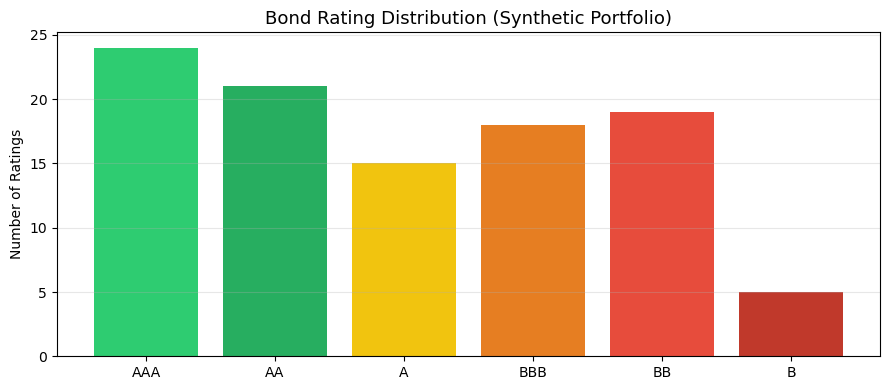

In [6]:
df_ratings = pd.read_sql("""
    SELECT rating, COUNT(*) as count
    FROM silver.stg_rating_history
    GROUP BY rating
    ORDER BY count DESC
""", engine)

RATING_ORDER = ['AAA','AA','A','BBB','BB','B','CCC']
df_ratings['rating'] = pd.Categorical(df_ratings['rating'], categories=RATING_ORDER, ordered=True)
df_ratings = df_ratings.sort_values('rating')

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(df_ratings['rating'], df_ratings['count'],
              color=['#2ecc71','#27ae60','#f1c40f','#e67e22','#e74c3c','#c0392b','#8e44ad'])
ax.set_title('Bond Rating Distribution (Synthetic Portfolio)', fontsize=13)
ax.set_ylabel('Number of Ratings')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Fallen Angels Detection — BBB→BB Downgrades (SCD Type 2)

In [7]:
df_fallen = pd.read_sql("""
    SELECT actual.bond_id, actual.agency,
           prev.rating    AS prev_rating,
           actual.rating  AS current_rating,
           actual.dbt_valid_from AS downgrade_date
    FROM snapshots.rating_history_snapshot actual
    JOIN snapshots.rating_history_snapshot prev
        ON actual.bond_id = prev.bond_id
        AND actual.agency = prev.agency
        AND prev.dbt_valid_to IS NOT NULL
    WHERE actual.dbt_valid_to IS NULL
      AND actual.rating = 'BB'
      AND prev.rating = 'BBB'
""", engine)

print(f'Fallen angels detected: {len(df_fallen)}')
df_fallen

Fallen angels detected: 0


,bond_id,agency,prev_rating,current_rating,downgrade_date


## 5. Spread in Context — Crisis periods

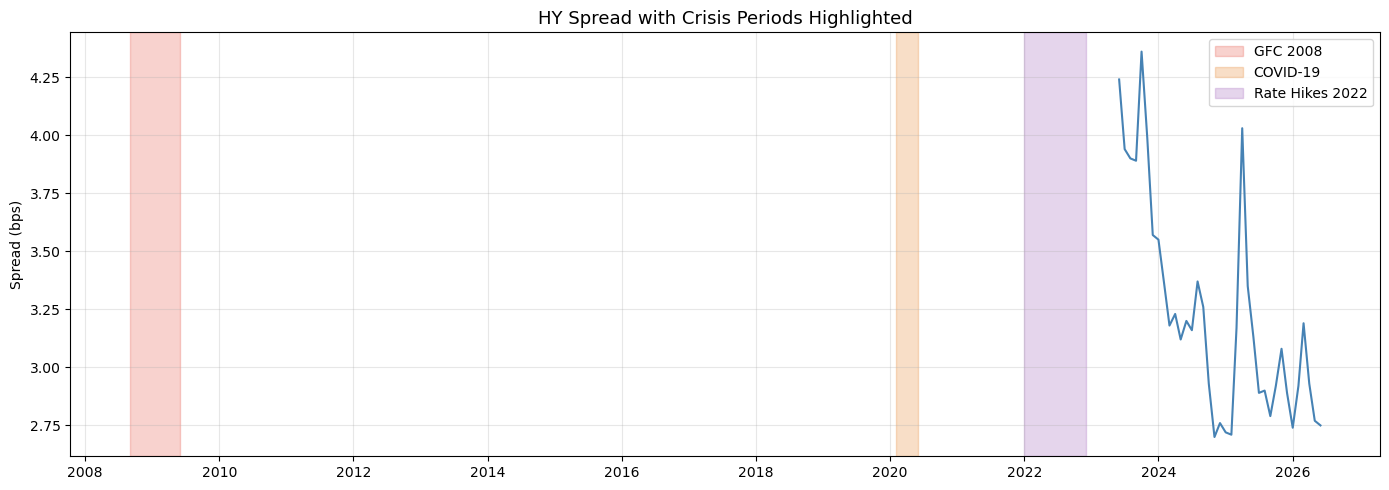

In [8]:
crisis_periods = [
    ('2008-09-01', '2009-06-01', 'GFC 2008'),
    ('2020-02-01', '2020-06-01', 'COVID-19'),
    ('2022-01-01', '2022-12-01', 'Rate Hikes 2022'),
]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df_monthly['month'], df_monthly['avg_spread'], color='steelblue', linewidth=1.5)

colors = ['#e74c3c', '#e67e22', '#9b59b6']
for (start, end, label), color in zip(crisis_periods, colors):
    ax.axvspan(pd.to_datetime(start), pd.to_datetime(end),
               alpha=0.25, color=color, label=label)

ax.set_title('HY Spread with Crisis Periods Highlighted', fontsize=13)
ax.set_ylabel('Spread (bps)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()